# Project B — H7N9 Human (bulk transcriptomics)

**Design:** 5 conditions (mock, H3N2, H7N7, H7N9, H5N1/VN1203) × 4 time points (3h, 7h, 12h, 24h) × 4 replicates

Run from the repo root. Input: `data/01_Data.txt` — outputs: `Results/` (both git-ignored).

## 0. Setup

### 0.1 Install packages (run once)

In [2]:
# install.packages(c("ggplot2", "ggrepel", "enrichR", "MASS", "BiocManager", "IRkernel"))
# BiocManager::install(c("limma", "fgsea"))

### 0.2 Load packages

In [3]:
library(limma)
library(ggplot2)
library(ggrepel)
library(enrichR)
library(MASS)

options(repr.plot.width = 7, repr.plot.height = 5)   # inline plot size

Welcome to enrichR
Checking connections ... 

Enrichr ... 
Connection is Live!

FlyEnrichr ... 
Connection is Live!

WormEnrichr ... 
Connection is Live!

YeastEnrichr ... 
Connection is Live!

FishEnrichr ... 
Connection is Live!

OxEnrichr ... 
Connection is Live!



### 0.3 Paths & output folder

In [4]:
data_file <- file.path("data", "01_Data.txt")
out_dir   <- "Results"                     # all figures/tables go here
dir.create(out_dir, showWarnings = FALSE)

# helper: save a ggplot into Results/ (PNG + PDF)
save_plot <- function(p, name, width = 7, height = 5) {
  ggsave(file.path(out_dir, paste0(name, ".png")), p, width = width, height = height, dpi = 300)
  ggsave(file.path(out_dir, paste0(name, ".pdf")), p, width = width, height = height)
  invisible(p)
}

### 0.4 Global settings (colours)

In [5]:
virus_cols <- c("mock" = "grey50", "H3N2" = "#1f77b4", "H7N7" = "#2ca02c",
                "H7N9" = "#d62728", "H5N1 (VN1203)" = "#ff7f0e")

## 1. Data import

In [6]:
data <- read.delim(data_file)
data <- as.matrix(data)
dim(data)   # genes x samples

[1] 19981    78

## 2. Sample metadata

### 2.1 Build metadata from column names (`virus_time_replicate`)

In [7]:
parts <- do.call(rbind, strsplit(colnames(data), "_"))
meta  <- data.frame(sample = colnames(data),
                    virus  = parts[, 1],
                    hour   = as.integer(sub("h$", "", parts[, 2])),
                    rep    = parts[, 3],
                    stringsAsFactors = FALSE)
meta$virus[meta$virus == "VN1203"] <- "H5N1 (VN1203)"
meta$virus  <- factor(meta$virus, levels = c("mock", "H3N2", "H7N7", "H7N9", "H5N1 (VN1203)"))
meta$hour_f <- factor(meta$hour, levels = c(3, 7, 12, 24), labels = paste0(c(3, 7, 12, 24), " h"))
rownames(meta) <- meta$sample
head(meta)

,sample,virus,hour,rep,hour_f
,<chr>,<fct>,<int>,<chr>,<fct>
H3N2_03h_1,H3N2_03h_1,H3N2,3,1,3 h
H3N2_03h_2,H3N2_03h_2,H3N2,3,2,3 h
H3N2_03h_4,H3N2_03h_4,H3N2,3,4,3 h
H3N2_07h_1,H3N2_07h_1,H3N2,7,1,7 h
H3N2_07h_2,H3N2_07h_2,H3N2,7,2,7 h
H3N2_07h_3,H3N2_07h_3,H3N2,7,3,7 h


### 2.2 Check missing samples

4 replicates expected per group; H3N2 and VN1203 have a missing sample at 3h.

In [8]:
table(meta$virus, meta$hour_f)

               
                3 h 7 h 12 h 24 h
  mock            4   4    4    4
  H3N2            3   4    4    4
  H7N7            4   4    4    4
  H7N9            4   4    4    4
  H5N1 (VN1203)   3   4    4    4

## 3. Filtering & transformation

In [9]:
data <- data[apply(data, 1, max) > 0, ]   # remove genes never expressed
logx <- log2(data + 1)                    # log2 transform
dim(logx)

[1] 19981    78

## 4. PCA

### 4.1 Functions

In [10]:
run_pca <- function(mat, meta, n_top = 2000, scale. = TRUE) {
  top <- names(sort(apply(mat, 1, var), decreasing = TRUE))[seq_len(n_top)]
  p   <- prcomp(t(mat[top, ]), center = TRUE, scale. = scale.)
  list(scores = cbind(as.data.frame(p$x[, 1:10]), meta[rownames(p$x), ]),
       var    = 100 * p$sdev^2 / sum(p$sdev^2),
       load   = p$rotation[, 1:10])
}

plot_pca <- function(res, x = "PC1", y = "PC2", title = "") {
  xi <- as.integer(sub("PC", "", x)); yi <- as.integer(sub("PC", "", y))
  ggplot(res$scores, aes(.data[[x]], .data[[y]], colour = virus, shape = hour_f)) +
    geom_hline(yintercept = 0, colour = "grey85") +
    geom_vline(xintercept = 0, colour = "grey85") +
    geom_point(size = 3, alpha = .85) +
    scale_colour_manual(values = virus_cols) +
    labs(title = title, colour = "Virus", shape = "Time",
         x = sprintf("%s (%.1f%%)", x, res$var[xi]),
         y = sprintf("%s (%.1f%%)", y, res$var[yi])) +
    theme_bw()
}

### 4.2 PCA — all samples

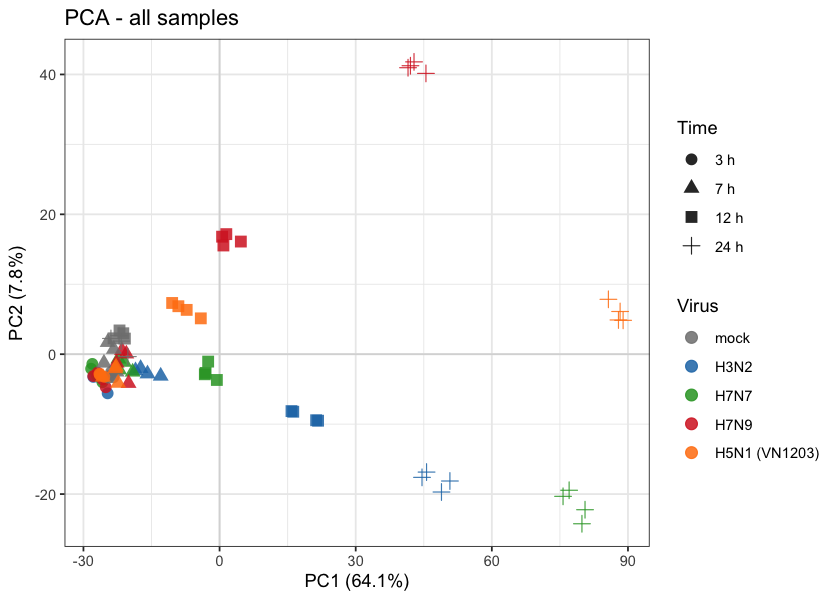

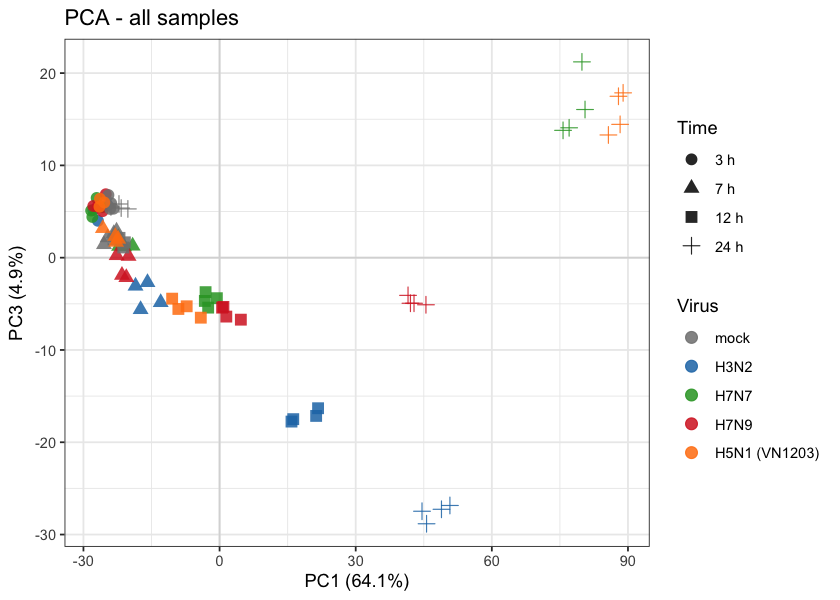

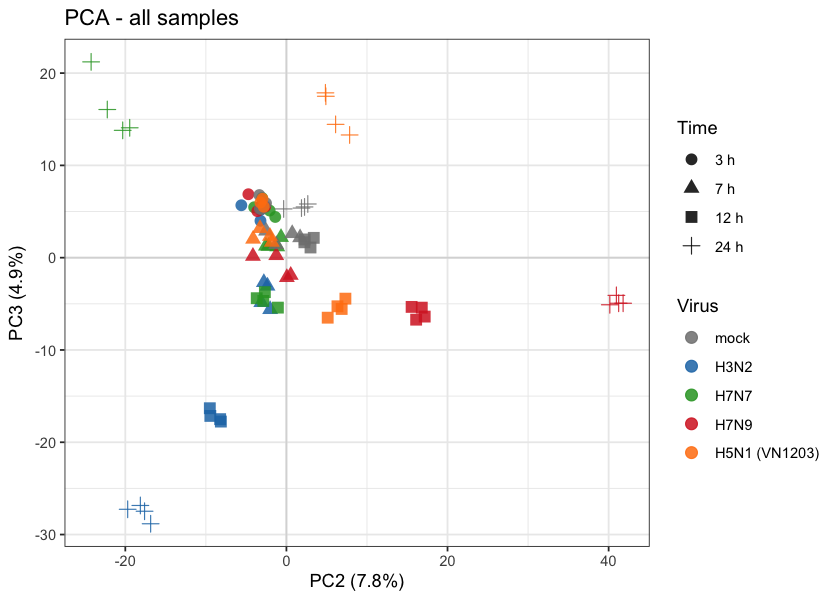

In [11]:
res <- run_pca(logx, meta)
p12 <- plot_pca(res, "PC1", "PC2", "PCA - all samples"); print(p12)
p13 <- plot_pca(res, "PC1", "PC3", "PCA - all samples"); print(p13)
p23 <- plot_pca(res, "PC2", "PC3", "PCA - all samples"); print(p23)

save_plot(p12, "PCA_all_PC1_PC2")
save_plot(p13, "PCA_all_PC1_PC3")
save_plot(p23, "PCA_all_PC2_PC3")
write.csv(res$scores, file.path(out_dir, "PCA_all_scores.csv"))

## 5. Differential expression (virus vs mock, per time point)

Data are already normalised (non-integer values) → limma on log2 data
(`eBayes` with `trend = TRUE`, i.e. "limma-trend"), not DESeq2/edgeR.

In [12]:
de_dir <- file.path(out_dir, "DE")
dir.create(de_dir, showWarnings = FALSE)

### 5.1 Parameters

In [13]:
lfc_thr  <- 1      # |log2FC| > 1  (fold change > 2)
padj_thr <- 0.05   # BH-adjusted p-value

### 5.2 Remove lowly expressed genes

In [14]:
expr <- logx[rowMeans(logx) > 1, rownames(meta)]
dim(expr)

[1] 19981    78

### 5.3 Design: one group per virus × time

In [15]:
meta$group <- factor(paste(sub("_.*", "", meta$sample), meta$hour, sep = "_"))  # e.g. H7N9_24
design <- model.matrix(~ 0 + group, data = meta)
colnames(design) <- levels(meta$group)

fit <- lmFit(expr, design)

### 5.4 Contrasts: each virus vs mock at the same time point

In [16]:
viruses <- c("H3N2", "H7N7", "H7N9", "VN1203")
hours   <- c(3, 7, 12, 24)
grid    <- expand.grid(virus = viruses, hour = hours, stringsAsFactors = FALSE)
contr_names <- paste0(grid$virus, "_", grid$hour, "h_vs_mock")
contr_def   <- paste0(grid$virus, "_", grid$hour, " - mock_", grid$hour)

cm <- makeContrasts(contrasts = contr_def, levels = design)
colnames(cm) <- contr_names
fit2 <- eBayes(contrasts.fit(fit, cm), trend = TRUE)

### 5.5 Volcano plot function

In [17]:
plot_volcano <- function(tt, title, n_lab = 15) {
  lab <- head(tt[tt$status != "NS", ], n_lab)   # tt is sorted by p-value
  ggplot(tt, aes(logFC, -log10(adj.P.Val), colour = status)) +
    geom_point(size = .8, alpha = .6) +
    geom_vline(xintercept = c(-lfc_thr, lfc_thr), linetype = 2, colour = "grey50") +
    geom_hline(yintercept = -log10(padj_thr),    linetype = 2, colour = "grey50") +
    geom_text_repel(data = lab, aes(label = gene), size = 3, colour = "black",
                    max.overlaps = Inf) +
    scale_colour_manual(values = c(Up = "#d62728", Down = "#1f77b4", NS = "grey75")) +
    labs(title = title,
         subtitle = sprintf("FDR (BH) < %.2f, |log2FC| > %g", padj_thr, lfc_thr),
         x = "log2 fold change (virus / mock)",
         y = "-log10 FDR (adjusted p-value)", colour = NULL) +
    theme_bw()
}

### 5.6 Tables + volcanos for every contrast (saved in `Results/DE`)

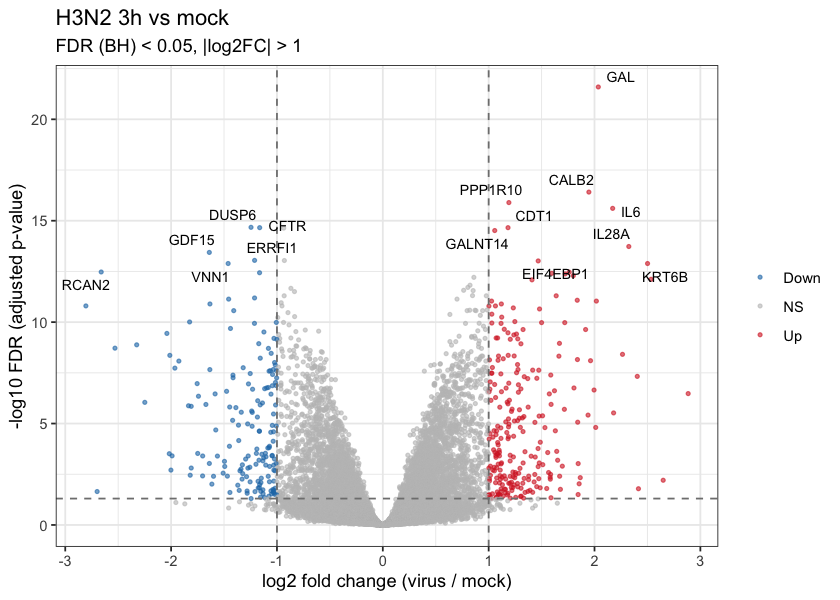

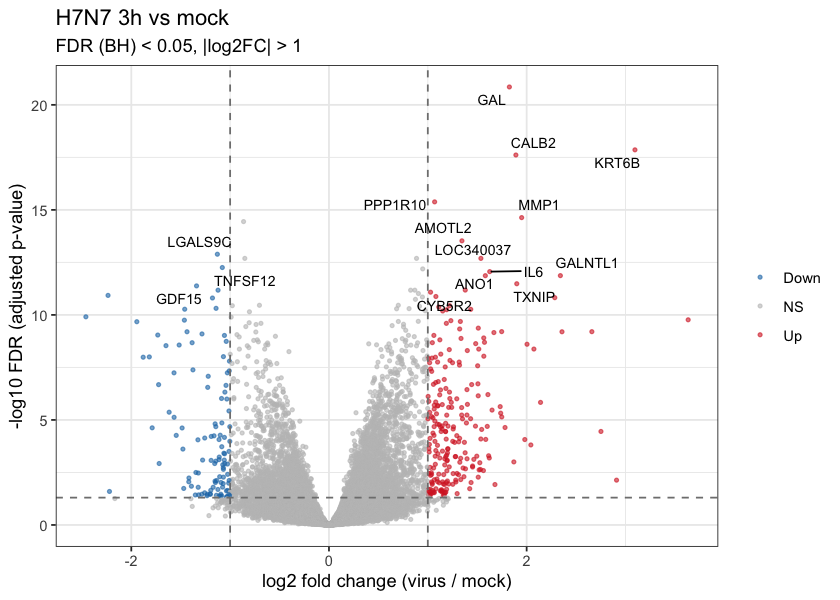

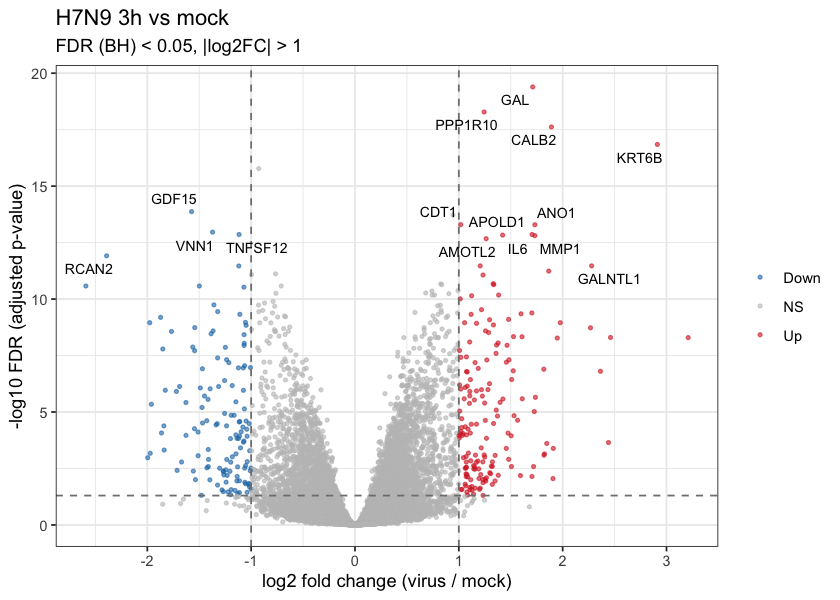

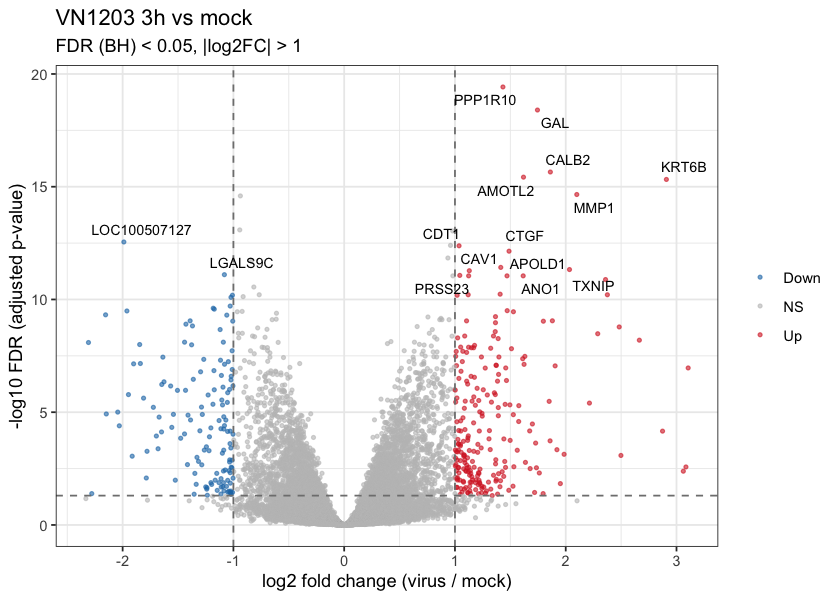

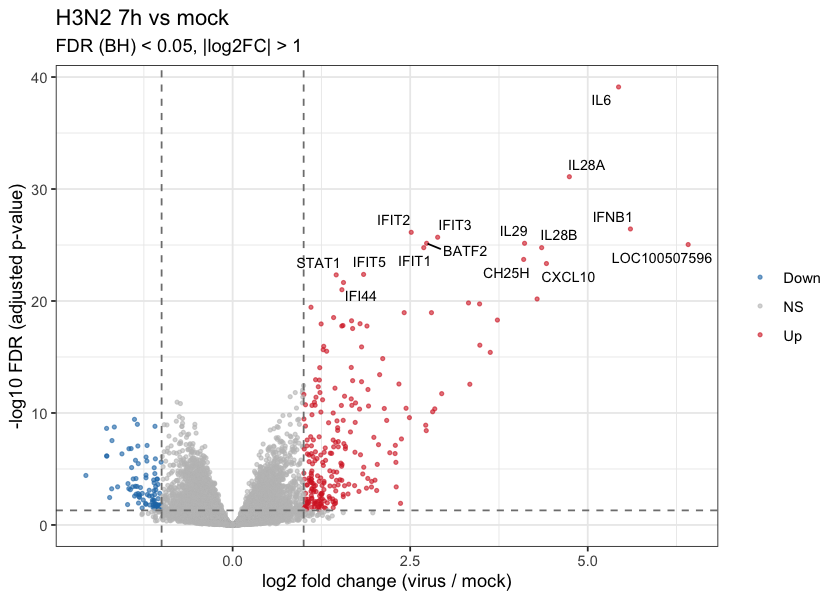

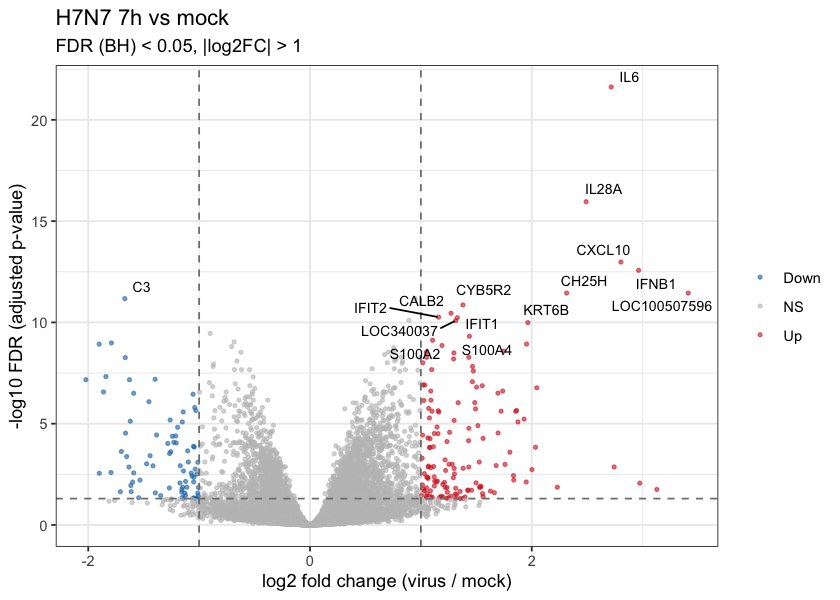

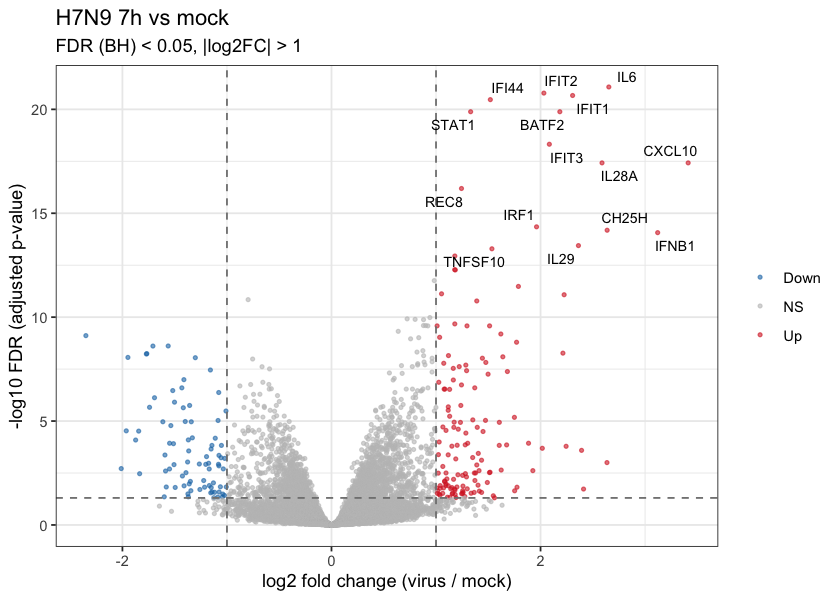

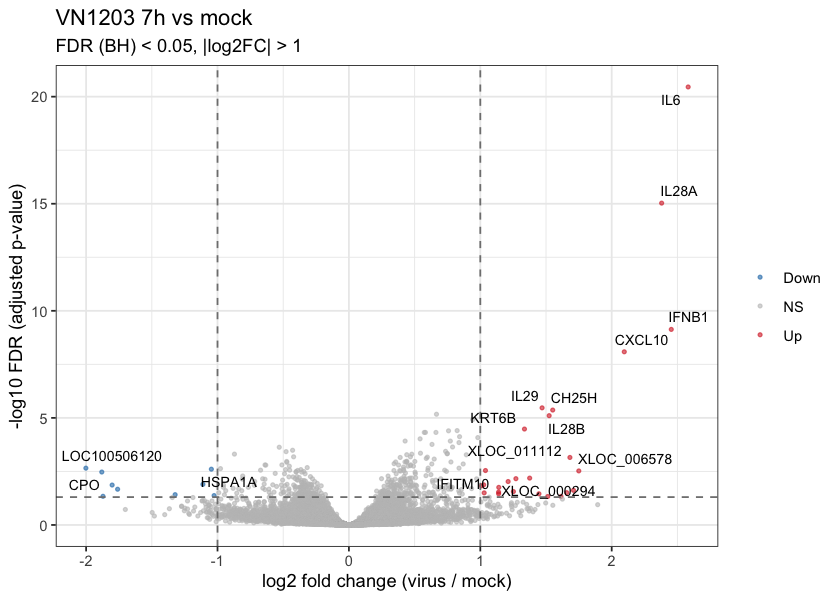

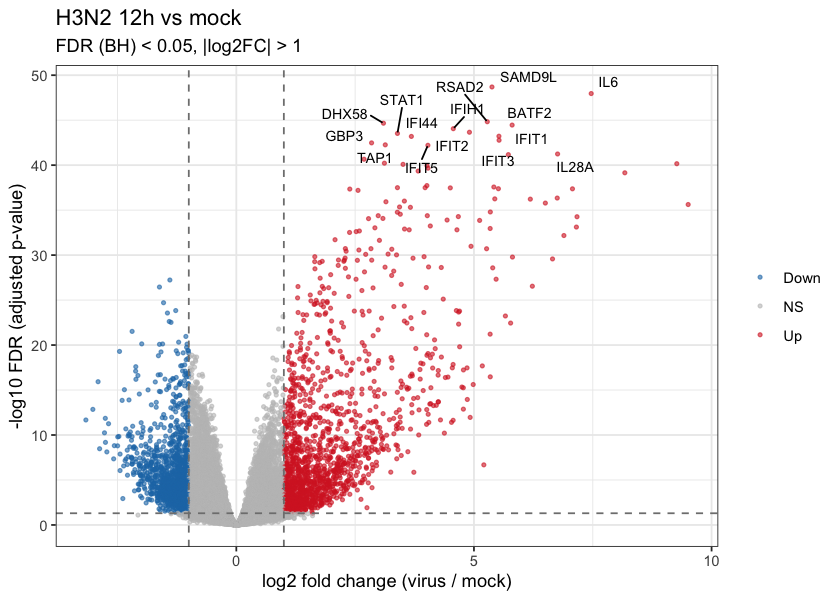

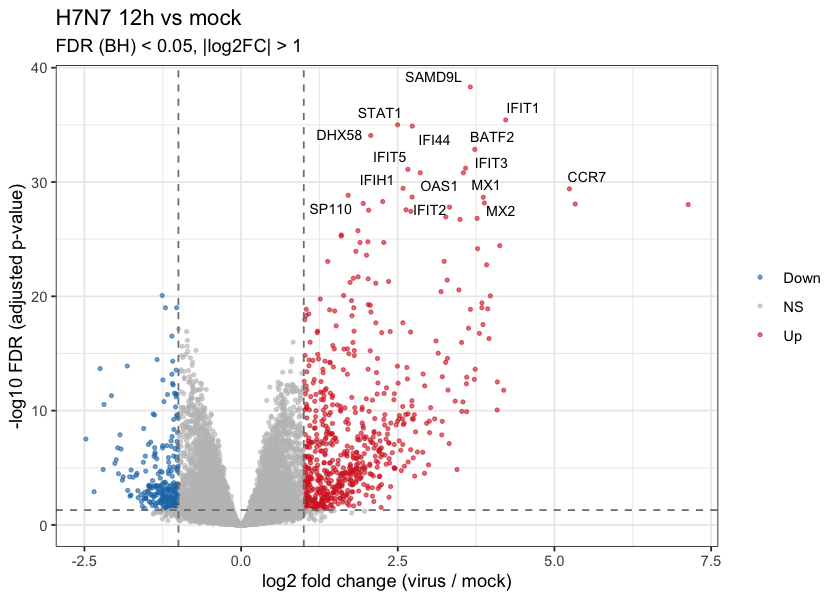

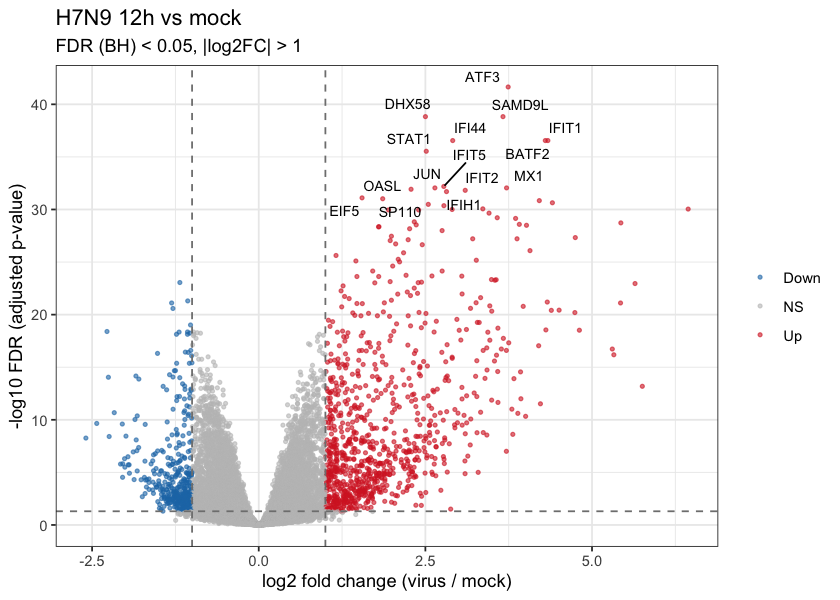

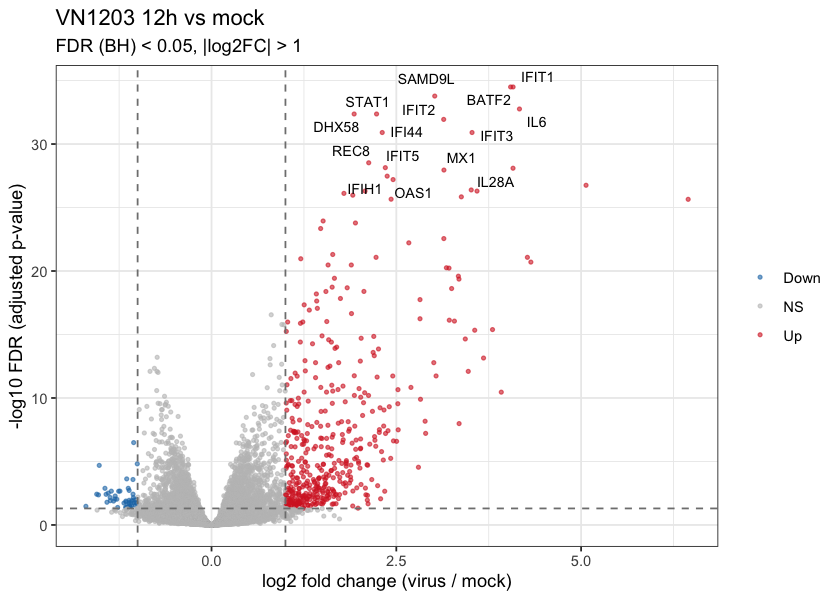

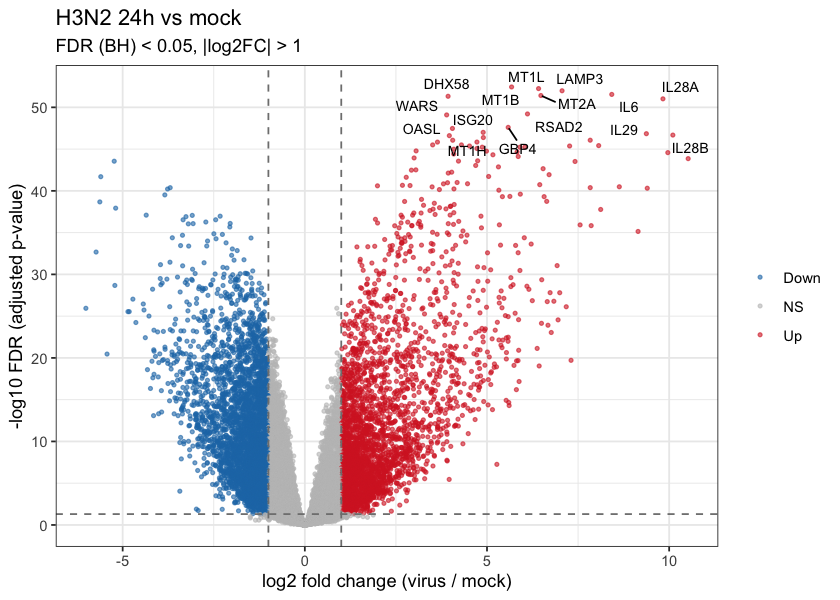

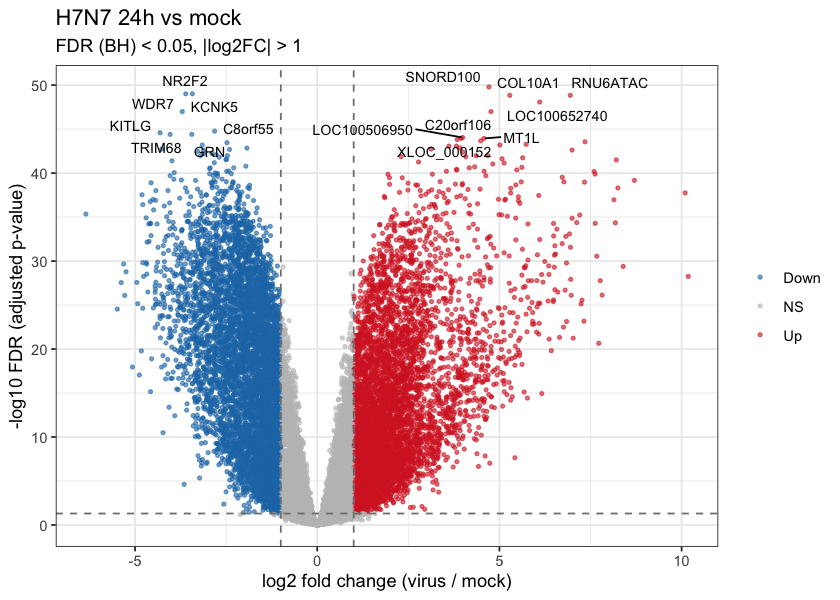

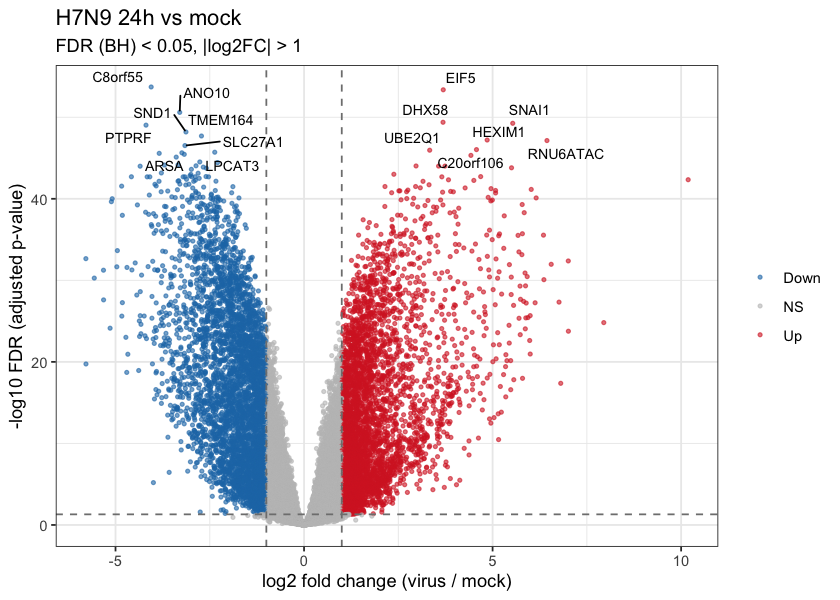

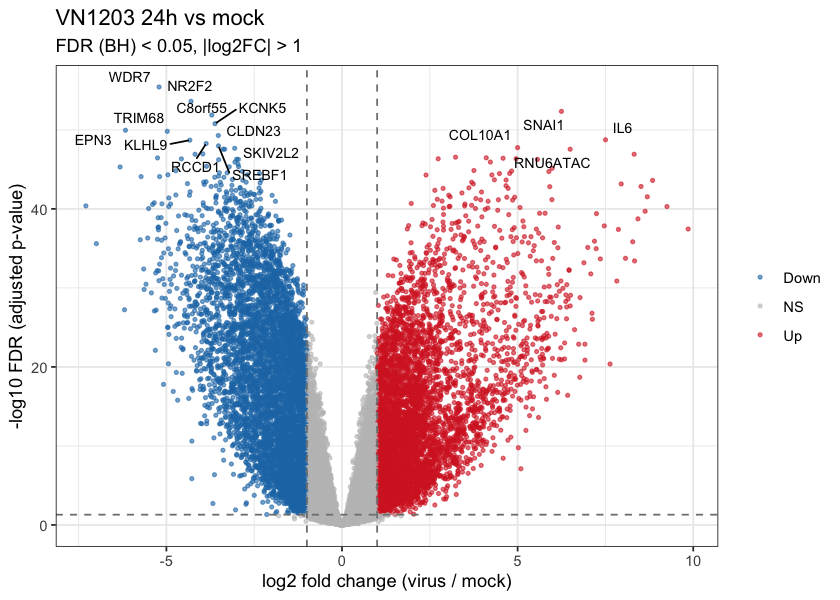

In [18]:
de_list <- list()
for (cn in contr_names) {
  tt <- topTable(fit2, coef = cn, number = Inf, sort.by = "P")
  tt$gene   <- rownames(tt)
  tt$status <- ifelse(tt$adj.P.Val < padj_thr & tt$logFC >  lfc_thr, "Up",
               ifelse(tt$adj.P.Val < padj_thr & tt$logFC < -lfc_thr, "Down", "NS"))
  de_list[[cn]] <- tt

  write.csv(tt, file.path(de_dir, paste0("DE_", cn, ".csv")), row.names = FALSE)
  p_vol <- plot_volcano(tt, gsub("_", " ", cn))
  print(p_vol)                                   # show in notebook
  save_plot(p_vol, file.path("DE", paste0("Volcano_", cn)))
}

### 5.7 Number of DEGs per virus and time point

In [19]:
deg_summary <- data.frame(
  contrast = contr_names,
  virus    = grid$virus,
  hour     = grid$hour,
  Up       = sapply(de_list, function(t) sum(t$status == "Up")),
  Down     = sapply(de_list, function(t) sum(t$status == "Down"))
)
write.csv(deg_summary, file.path(de_dir, "DEG_summary.csv"), row.names = FALSE)
deg_summary

,contrast,virus,hour,Up,Down
,<chr>,<chr>,<dbl>,<int>,<int>
H3N2_3h_vs_mock,H3N2_3h_vs_mock,H3N2,3,247,164
H7N7_3h_vs_mock,H7N7_3h_vs_mock,H7N7,3,234,112
H7N9_3h_vs_mock,H7N9_3h_vs_mock,H7N9,3,169,131
VN1203_3h_vs_mock,VN1203_3h_vs_mock,VN1203,3,232,135
H3N2_7h_vs_mock,H3N2_7h_vs_mock,H3N2,7,243,86
H7N7_7h_vs_mock,H7N7_7h_vs_mock,H7N7,7,145,76
H7N9_7h_vs_mock,H7N9_7h_vs_mock,H7N9,7,144,81
VN1203_7h_vs_mock,VN1203_7h_vs_mock,VN1203,7,26,9
H3N2_12h_vs_mock,H3N2_12h_vs_mock,H3N2,12,1505,1273


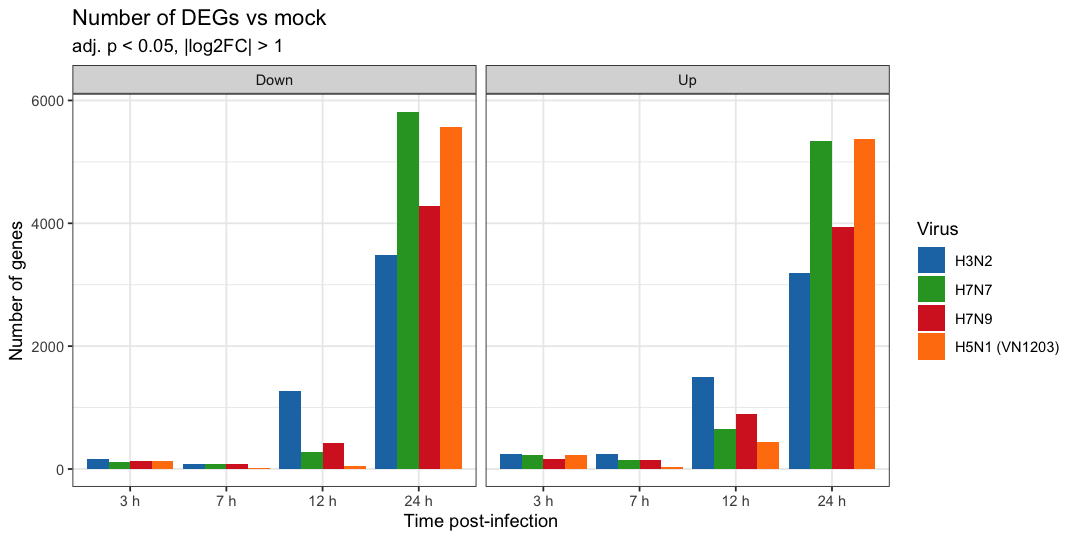

In [20]:
deg_long <- rbind(data.frame(deg_summary[, c("virus", "hour")], direction = "Up",   n = deg_summary$Up),
                  data.frame(deg_summary[, c("virus", "hour")], direction = "Down", n = deg_summary$Down))
deg_long$virus  <- factor(sub("VN1203", "H5N1 (VN1203)", deg_long$virus), levels = names(virus_cols)[-1])
deg_long$hour_f <- factor(paste0(deg_long$hour, " h"), levels = paste0(hours, " h"))

p_deg <- ggplot(deg_long, aes(hour_f, n, fill = virus)) +
  geom_col(position = "dodge") +
  facet_wrap(~ direction) +
  scale_fill_manual(values = virus_cols) +
  labs(title = "Number of DEGs vs mock",
       subtitle = sprintf("adj. p < %.2f, |log2FC| > %g", padj_thr, lfc_thr),
       x = "Time post-infection", y = "Number of genes", fill = "Virus") +
  theme_bw()

options(repr.plot.width = 9, repr.plot.height = 4.5)
print(p_deg)
save_plot(p_deg, "DEG_number_per_virus_time", width = 9, height = 4.5)

### 5.8 Volcano H7N9 vs other viruses (12h and 24h)

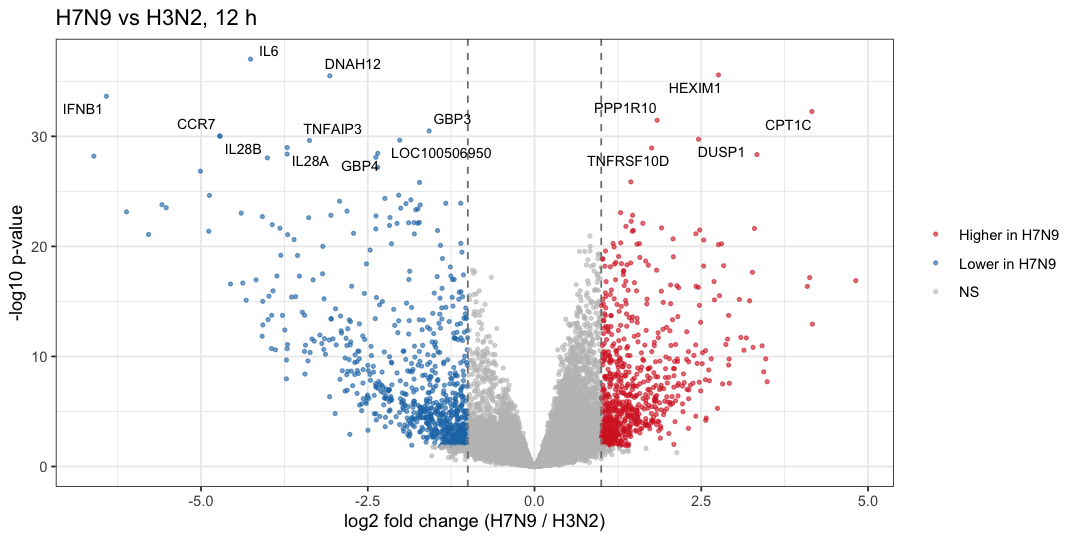

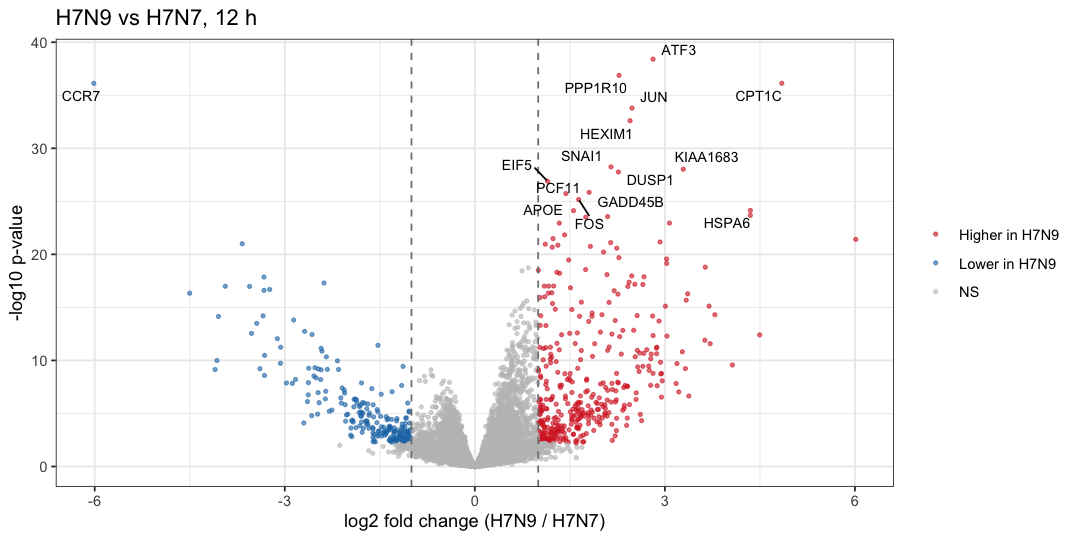

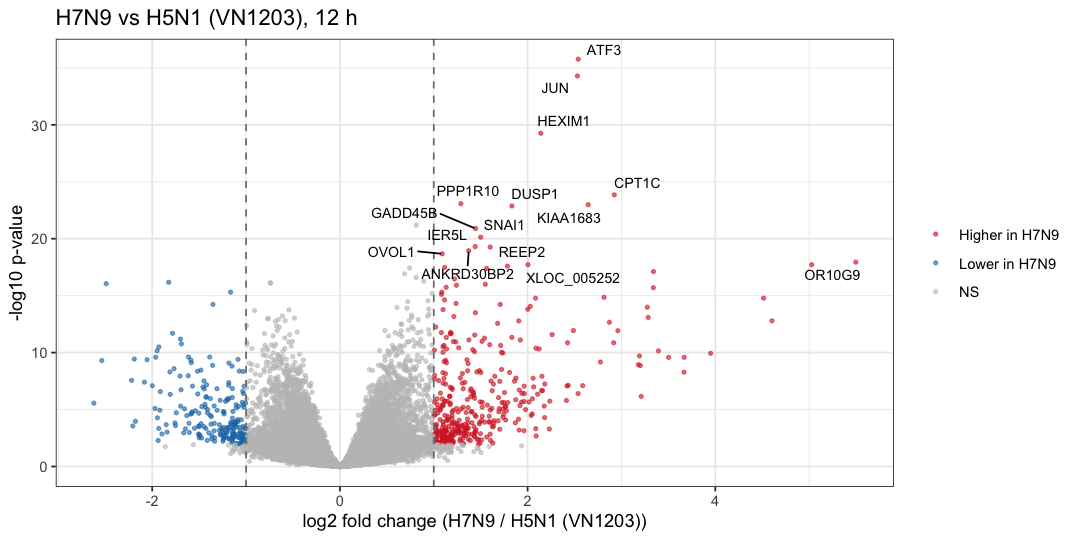

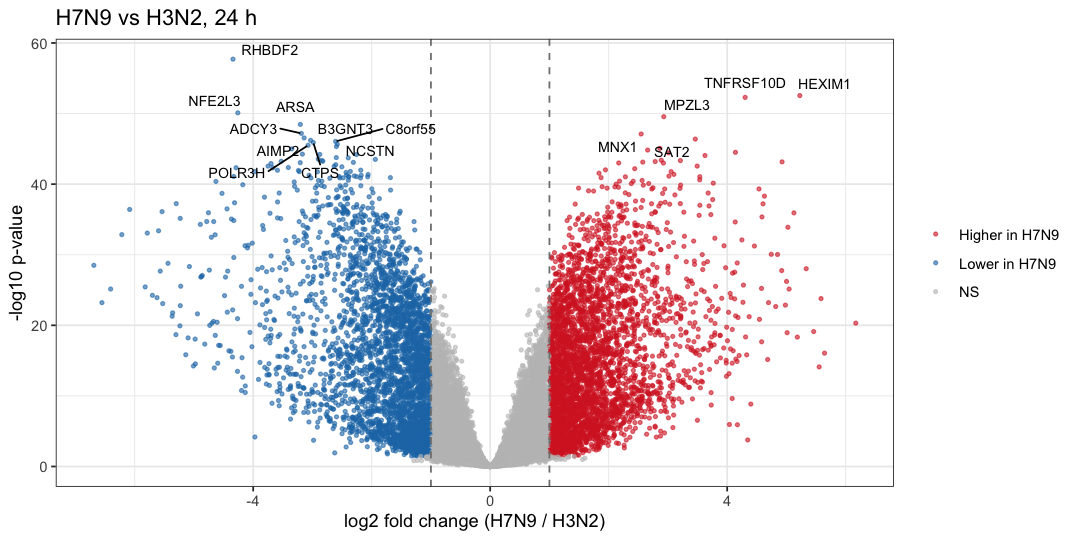

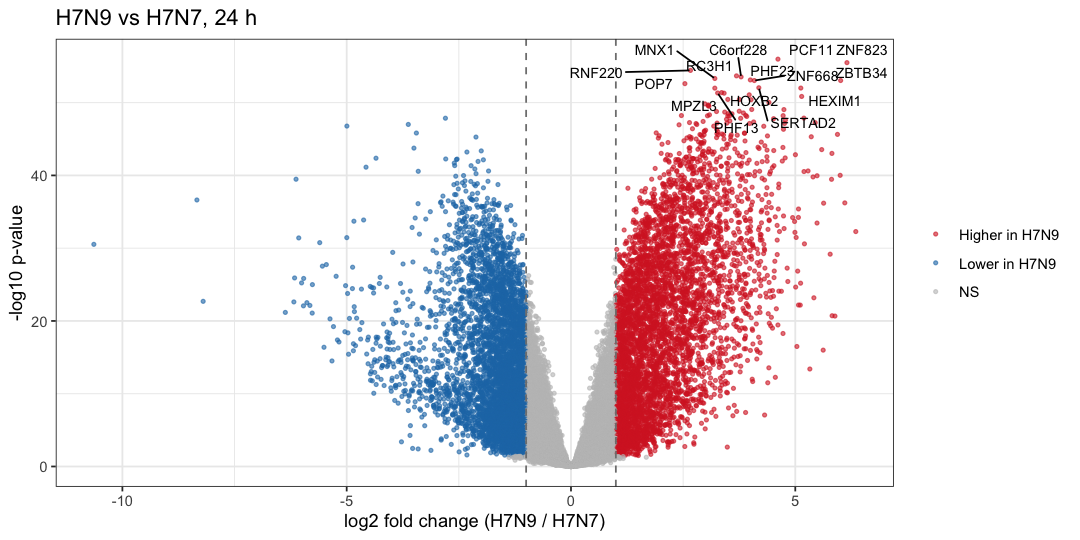

comparison,other_virus,hour,higher_in_H7N9,lower_in_H7N9
<chr>,<chr>,<dbl>,<int>,<int>
H7N9_vs_H3N2_12h,H3N2,12,704,781
H7N9_vs_H7N7_12h,H7N7,12,386,220
H7N9_vs_VN1203_12h,H5N1 (VN1203),12,378,206
H7N9_vs_H3N2_24h,H3N2,24,3604,3283
H7N9_vs_H7N7_24h,H7N7,24,4551,4997
H7N9_vs_VN1203_24h,H5N1 (VN1203),24,4009,4060


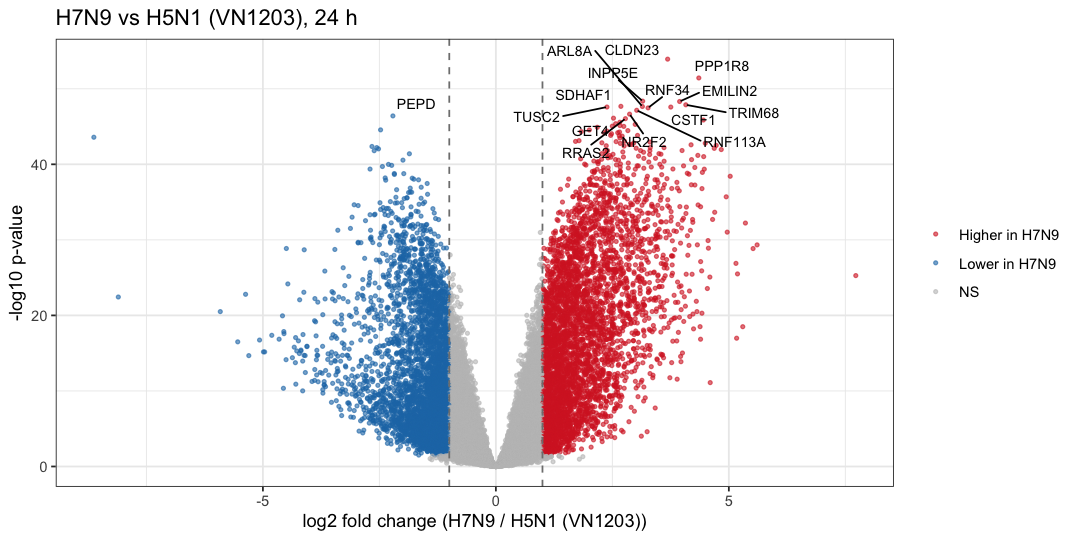

In [21]:
cmp_dir <- file.path(out_dir, "DE_H7N9_vs_virus")
dir.create(cmp_dir, showWarnings = FALSE)

others2 <- c("H3N2", "H7N7", "VN1203")
hours2  <- c(12, 24)
grid2   <- expand.grid(other = others2, hour = hours2, stringsAsFactors = FALSE)

cmp_names <- paste0("H7N9_vs_", grid2$other, "_", grid2$hour, "h")
cmp_def   <- paste0("H7N9_", grid2$hour, " - ", grid2$other, "_", grid2$hour)

cm_cmp   <- makeContrasts(contrasts = cmp_def, levels = design)
colnames(cm_cmp) <- cmp_names
fit_cmp  <- eBayes(contrasts.fit(fit, cm_cmp), trend = TRUE)

plot_volcano_vs <- function(tt, title, other_label, n_lab = 15) {
  lab <- head(tt[tt$status != "NS", ], n_lab)          # tt is sorted by p-value
  ggplot(tt, aes(logFC, -log10(P.Value), colour = status)) +
    geom_point(size = .8, alpha = .6) +
    geom_vline(xintercept = c(-lfc_thr, lfc_thr), linetype = 2, colour = "grey50") +
    geom_text_repel(data = lab, aes(label = gene), size = 3, colour = "black",
                    max.overlaps = Inf) +
    scale_colour_manual(values = c("Higher in H7N9" = "#d62728",
                                   "Lower in H7N9"  = "#1f77b4",
                                   NS = "grey75")) +
    labs(title = title,
         x = sprintf("log2 fold change (H7N9 / %s)", other_label),
         y = "-log10 p-value", colour = NULL) +
    theme_bw()
}

cmp_list <- list()
for (i in seq_along(cmp_names)) {
  cn <- cmp_names[i]
  tt <- topTable(fit_cmp, coef = cn, number = Inf, sort.by = "P")
  tt$gene   <- rownames(tt)
  tt$status <- ifelse(tt$adj.P.Val < padj_thr & tt$logFC >  lfc_thr, "Higher in H7N9",
               ifelse(tt$adj.P.Val < padj_thr & tt$logFC < -lfc_thr, "Lower in H7N9", "NS"))
  cmp_list[[cn]] <- tt

  other_label <- sub("VN1203", "H5N1 (VN1203)", grid2$other[i])
  title <- sprintf("H7N9 vs %s, %d h", other_label, grid2$hour[i])

  write.csv(tt, file.path(cmp_dir, paste0("DE_", cn, ".csv")), row.names = FALSE)
  p <- plot_volcano_vs(tt, title, other_label)
  print(p)
  save_plot(p, file.path("DE_H7N9_vs_virus", paste0("Volcano_", cn)))
}

# Number of genes per comparison
cmp_summary <- data.frame(
  comparison     = cmp_names,
  other_virus    = sub("VN1203", "H5N1 (VN1203)", grid2$other),
  hour           = grid2$hour,
  higher_in_H7N9 = sapply(cmp_list, function(t) sum(t$status == "Higher in H7N9")),
  lower_in_H7N9  = sapply(cmp_list, function(t) sum(t$status == "Lower in H7N9")),
  row.names = NULL
)
write.csv(cmp_summary, file.path(cmp_dir, "H7N9_vs_virus_summary.csv"), row.names = FALSE)
cmp_summary


## 6. Functional enrichment (enrichR)

ORA (over-representation analysis) with enrichR on the DEGs of each contrast (virus vs mock), **Up and Down separately**.
Databases: GO Biological Process, KEGG, Reactome. Significant terms: adj. p < 0.05.

### 6.1 Parameters

In [22]:
enr_dir <- file.path(out_dir, "Enrichment")
dir.create(enr_dir, showWarnings = FALSE)

setEnrichrSite("Enrichr")
dbs <- c("GO_Biological_Process_2023", "KEGG_2021_Human", "Reactome_2022")
# to check available database names: View(listEnrichrDbs())
min_genes <- 10   # skip lists with fewer DEGs

Connection changed to https://maayanlab.cloud/Enrichr/

Connection is Live!



### 6.2 Run enrichR on every contrast (Up and Down separately, saved in `Results/Enrichment`)

In [23]:
enr_res <- list()
for (cn in contr_names) {
  tt <- de_list[[cn]]
  for (dir_name in c("Up", "Down")) {
    genes <- tt$gene[tt$status == dir_name]
    if (length(genes) < min_genes) next
    res_enr <- enrichr(genes, dbs)
    Sys.sleep(1)                                   # be polite to the server
    for (db in dbs) {
      r <- res_enr[[db]]
      if (is.null(r) || nrow(r) == 0) next
      r$contrast <- cn; r$direction <- dir_name; r$db <- db
      enr_res[[paste(cn, dir_name, db, sep = "|")]] <- r
    }
  }
}

enr_all <- do.call(rbind, enr_res)
rownames(enr_all) <- NULL
enr_all$virus   <- sub("_.*", "", enr_all$contrast)
enr_all$hour    <- as.integer(sub("h", "", sapply(strsplit(enr_all$contrast, "_"), `[`, 2)))
enr_all$n_genes <- as.integer(sub("/.*", "", enr_all$Overlap))

enr_sig <- enr_all[enr_all$Adjusted.P.value < 0.05, ]
write.csv(enr_all, file.path(enr_dir, "enrichR_all.csv"), row.names = FALSE)
write.csv(enr_sig, file.path(enr_dir, "enrichR_significant.csv"), row.names = FALSE)

table(enr_sig$contrast, enr_sig$direction)        # number of significant terms

### 6.3 Top pathways for H7N9 at 24 h

In [ ]:
top_terms <- function(cn, dir_name, db_name, n = 10) {
  d <- enr_sig[enr_sig$contrast == cn & enr_sig$direction == dir_name & enr_sig$db == db_name, ]
  head(d[order(d$Adjusted.P.value), c("Term", "Overlap", "Adjusted.P.value")], n)
}
print(top_terms("H7N9_24h_vs_mock", "Up",   "Reactome_2022"))
print(top_terms("H7N9_24h_vs_mock", "Down", "Reactome_2022"))

### 6.4 Dot plots: compare the 4 viruses at 12 h and 24 h (top 5 terms per contrast)

In [ ]:
plot_enr_compare <- function(db_name, dir_name, hrs = c(12, 24), n_top = 5) {
  d <- enr_sig[enr_sig$db == db_name & enr_sig$direction == dir_name & enr_sig$hour %in% hrs, ]
  if (nrow(d) == 0) return(NULL)
  keep <- unique(unlist(lapply(split(d, d$contrast),
                 function(x) head(x$Term[order(x$Adjusted.P.value)], n_top))))
  d <- d[d$Term %in% keep, ]
  d$virus <- factor(sub("VN1203", "H5N1 (VN1203)", d$virus), levels = names(virus_cols)[-1])
  lab_levels <- paste0(rep(levels(d$virus), times = length(hrs)), " ", rep(hrs, each = 4), "h")
  d$sample_lab <- factor(paste0(d$virus, " ", d$hour, "h"), levels = lab_levels)
  d$Term <- substr(sub(" \\(GO:.*\\)$", "", d$Term), 1, 60)   # shorten long names

  ggplot(d, aes(sample_lab, Term, size = n_genes, colour = -log10(Adjusted.P.value))) +
    geom_point() +
    scale_x_discrete(drop = FALSE) +
    scale_colour_gradient(low = "#fcbba1", high = "#a50f15") +
    labs(title = paste(db_name, "-", dir_name, "genes"),
         x = NULL, y = NULL, size = "Genes", colour = "-log10 adj. p") +
    theme_bw() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
}

options(repr.plot.width = 11, repr.plot.height = 8)
for (db in dbs) for (dir_name in c("Up", "Down")) {
  p <- plot_enr_compare(db, dir_name)
  if (is.null(p)) next
  print(p)
  save_plot(p, file.path("Enrichment", paste0("Dotplot_", db, "_", dir_name)), width = 11, height = 8)
}

### 6.5 GSEA (fgsea): why and setup

**Problem with ORA at 24 h:** H7N7/H5N1 have >5000 Up DEGs (~25% of the genome), so almost every pathway overlaps the list by chance → almost nothing significant.

**GSEA** uses **all genes**, ranked by the limma t-statistic (virus vs mock), with no DEG threshold. For each pathway it tests whether its genes sit at the top (activated) or bottom (repressed) of the ranking.
- **NES > 0** → pathway **activated** by the virus; **NES < 0** → **repressed**. Significant: adj. p < 0.05.
- Gene sets (downloaded from Enrichr into `data/genesets/`): **MSigDB Hallmark** (50 broad processes, best for the overall comparison), Reactome, KEGG, GO BP.
- Runtime: ~15 min for all 16 contrasts. Results in `Results/GSEA`.

In [ ]:
library(fgsea)

gsea_dir <- file.path(out_dir, "GSEA"); dir.create(gsea_dir, showWarnings = FALSE)
gs_dir   <- file.path("data", "genesets"); dir.create(gs_dir, showWarnings = FALSE)
gsea_libs <- c("MSigDB_Hallmark_2020", "Reactome_2022", "KEGG_2021_Human", "GO_Biological_Process_2023")

# read a .gmt file (one gene set per line: name, description, genes...) into a named list
read_gmt <- function(f) {
  l <- strsplit(readLines(f, warn = FALSE), "\t")
  s <- lapply(l, function(x) { g <- sub(",.*", "", x[-(1:2)]); unique(g[g != ""]) })
  names(s) <- sapply(l, function(x) x[1])
  s
}

# download each library from Enrichr once, then read it
gene_sets <- lapply(gsea_libs, function(lib) {
  f <- file.path(gs_dir, paste0(lib, ".gmt"))
  if (!file.exists(f))
    download.file(paste0("https://maayanlab.cloud/Enrichr/geneSetLibrary?mode=text&libraryName=", lib), f, quiet = TRUE)
  read_gmt(f)
})
names(gene_sets) <- gsea_libs

# helpers for plots
short_term <- function(x) substr(sub("\\s*(\\(GO:[0-9]+\\)|R-HSA-[0-9]+)$", "", x), 1, 60)
contrast_label <- function(virus, hour, hrs = hours) {
  v <- sub("VN1203", "H5N1", virus)
  factor(paste0(v, " ", hour, "h"),
         levels = paste0(rep(c("H3N2", "H7N7", "H7N9", "H5N1"), times = length(hrs)), " ", rep(hrs, each = 4), "h"))
}

sapply(gene_sets, length)   # number of gene sets per library

### 6.6 Run GSEA on every contrast (~15 min)

In [ ]:
gsea_res <- list()
set.seed(42)                                        # reproducible p-values
for (cn in contr_names) {
  tt    <- de_list[[cn]]
  ranks <- sort(setNames(tt$t, tt$gene), decreasing = TRUE)   # all genes ranked by limma t
  for (lib in gsea_libs) {
    r <- suppressWarnings(fgsea(gene_sets[[lib]], ranks, minSize = 15, maxSize = 500))
    r$leadingEdge <- sapply(r$leadingEdge, paste, collapse = ";")   # core genes driving the result
    r$contrast <- cn; r$db <- lib
    gsea_res[[paste(cn, lib, sep = "|")]] <- as.data.frame(r)
  }
  message(cn, " done")                              # progress
}

gsea_all <- do.call(rbind, gsea_res)
rownames(gsea_all) <- NULL
gsea_all$virus     <- sub("_.*", "", gsea_all$contrast)
gsea_all$hour      <- as.integer(sub("h", "", sapply(strsplit(gsea_all$contrast, "_"), function(x) x[2])))
gsea_all$direction <- ifelse(gsea_all$NES > 0, "Activated", "Repressed")

gsea_sig <- gsea_all[!is.na(gsea_all$padj) & gsea_all$padj < 0.05, ]
write.csv(gsea_all, file.path(gsea_dir, "GSEA_all.csv"), row.names = FALSE)
write.csv(gsea_sig, file.path(gsea_dir, "GSEA_significant.csv"), row.names = FALSE)

table(factor(gsea_sig$contrast, levels = contr_names), gsea_sig$direction)   # significant pathways

### 6.7 Hallmark heatmap: all viruses × all time points (main comparison figure)

Red = activated, blue = repressed vs mock; `*` = adj. p < 0.05. Only Hallmarks significant in at least one contrast are shown.

In [ ]:
h <- gsea_all[gsea_all$db == "MSigDB_Hallmark_2020", ]
h <- h[h$pathway %in% unique(gsea_sig$pathway[gsea_sig$db == "MSigDB_Hallmark_2020"]), ]
h$label   <- contrast_label(h$virus, h$hour)
h$pathway <- factor(h$pathway, levels = names(sort(tapply(h$NES, h$pathway, mean))))
h$star    <- ifelse(!is.na(h$padj) & h$padj < 0.05, "*", "")

p_hall <- ggplot(h, aes(label, pathway, fill = NES)) +
  geom_tile(colour = "white") +
  geom_text(aes(label = star), size = 4, vjust = 0.75) +
  geom_vline(xintercept = c(4.5, 8.5, 12.5), colour = "grey40") +     # separate time points
  scale_fill_gradient2(low = "#2166ac", mid = "white", high = "#b2182b", midpoint = 0) +
  labs(title = "GSEA - MSigDB Hallmark (virus vs mock)",
       subtitle = "red = activated, blue = repressed;  * adj. p < 0.05",
       x = NULL, y = NULL) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1), panel.grid = element_blank())

options(repr.plot.width = 12, repr.plot.height = 10)
print(p_hall)
save_plot(p_hall, file.path("GSEA", "Heatmap_Hallmark"), width = 12, height = 10)

### 6.8 Top activated / repressed pathways for H7N9 (12 h and 24 h)

In [ ]:
plot_gsea_top <- function(cn, lib, n = 10) {
  d  <- gsea_sig[gsea_sig$contrast == cn & gsea_sig$db == lib, ]
  if (nrow(d) == 0) return(NULL)
  up <- d[d$NES > 0, ]; up <- head(up[order(up$padj), ], n)
  dn <- d[d$NES < 0, ]; dn <- head(dn[order(dn$padj), ], n)
  d  <- rbind(up, dn)
  d$term <- short_term(d$pathway)
  d$term <- factor(d$term, levels = unique(d$term[order(d$NES)]))
  ggplot(d, aes(NES, term, fill = NES > 0)) +
    geom_col() +
    scale_fill_manual(values = c(`TRUE` = "#b2182b", `FALSE` = "#2166ac"),
                      labels = c(`TRUE` = "Activated", `FALSE` = "Repressed")) +
    labs(title = paste(gsub("_", " ", cn), "-", lib), x = "NES", y = NULL, fill = NULL) +
    theme_bw()
}

options(repr.plot.width = 10, repr.plot.height = 7)
for (lib in c("MSigDB_Hallmark_2020", "Reactome_2022")) for (hr in c(12, 24)) {
  cn <- paste0("H7N9_", hr, "h_vs_mock")
  p  <- plot_gsea_top(cn, lib)
  if (is.null(p)) next
  print(p)
  save_plot(p, file.path("GSEA", paste0("Top_", cn, "_", lib)), width = 10, height = 7)
}

### 6.9 Dot plots: compare the 4 viruses at 12 h and 24 h (Reactome, KEGG, GO BP)

Top 3 activated + top 3 repressed pathways per contrast. Colour = NES (red activated, blue repressed), size = significance.

In [ ]:
plot_gsea_compare <- function(lib, hrs = c(12, 24), n_top = 3) {
  d <- gsea_sig[gsea_sig$db == lib & gsea_sig$hour %in% hrs, ]
  if (nrow(d) == 0) return(NULL)
  pick <- function(x) {
    up <- x[x$NES > 0, ]; dn <- x[x$NES < 0, ]
    c(head(up$pathway[order(up$padj)], n_top), head(dn$pathway[order(dn$padj)], n_top))
  }
  keep <- unique(unlist(lapply(split(d, d$contrast), pick)))
  d <- d[d$pathway %in% keep, ]
  d$label <- contrast_label(d$virus, d$hour, hrs)
  d$term  <- short_term(d$pathway)
  d$term  <- factor(d$term, levels = names(sort(tapply(d$NES, d$term, mean))))
  ggplot(d, aes(label, term, colour = NES, size = -log10(padj))) +
    geom_point() +
    scale_x_discrete(drop = FALSE) +
    scale_colour_gradient2(low = "#2166ac", mid = "grey85", high = "#b2182b", midpoint = 0) +
    labs(title = paste("GSEA -", lib), subtitle = "significant pathways only (adj. p < 0.05)",
         x = NULL, y = NULL, size = "-log10 adj. p") +
    theme_bw() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
}

options(repr.plot.width = 11, repr.plot.height = 8)
for (lib in c("Reactome_2022", "KEGG_2021_Human", "GO_Biological_Process_2023")) {
  p <- plot_gsea_compare(lib)
  if (is.null(p)) next
  print(p)
  save_plot(p, file.path("GSEA", paste0("Dotplot_", lib)), width = 11, height = 8)
}

### 6.10 Direct comparison: H7N9 vs each virus (limma)

Sections 5–6.9 compare each virus **vs mock**. Here we compare **H7N9 directly against each other virus** at the same time point (H7N9 vs H3N2, vs H7N7, vs H5N1), using the same limma model (`fit`) from section 5.
- **Up** = higher in H7N9 than in the other virus; **Down** = lower in H7N9.
- **Fewer DEGs = H7N9 more similar to that virus** (Question 1). Results in `Results/H7N9_vs_viruses`.

In [ ]:
others   <- c("H3N2", "H7N7", "VN1203")
grid_h7  <- expand.grid(other = others, hour = hours, stringsAsFactors = FALSE)
h7_names <- paste0("H7N9_vs_", grid_h7$other, "_", grid_h7$hour, "h")         # e.g. H7N9_vs_H3N2_24h
h7_def   <- paste0("H7N9_", grid_h7$hour, " - ", grid_h7$other, "_", grid_h7$hour)

cm_h7 <- makeContrasts(contrasts = h7_def, levels = design)
colnames(cm_h7) <- h7_names
fit_h7 <- eBayes(contrasts.fit(fit, cm_h7), trend = TRUE)

h7_dir <- file.path(out_dir, "H7N9_vs_viruses"); dir.create(h7_dir, showWarnings = FALSE)
h7_list <- list()
for (cn in h7_names) {
  tt <- topTable(fit_h7, coef = cn, number = Inf, sort.by = "P")
  tt$gene   <- rownames(tt)
  tt$status <- ifelse(tt$adj.P.Val < padj_thr & tt$logFC >  lfc_thr, "Up",
               ifelse(tt$adj.P.Val < padj_thr & tt$logFC < -lfc_thr, "Down", "NS"))
  h7_list[[cn]] <- tt
  write.csv(tt, file.path(h7_dir, paste0("DE_", cn, ".csv")), row.names = FALSE)
}

h7_deg <- data.frame(other = sub("VN1203", "H5N1", grid_h7$other), hour = grid_h7$hour,
                     Up   = sapply(h7_list, function(t) sum(t$status == "Up")),
                     Down = sapply(h7_list, function(t) sum(t$status == "Down")))
h7_deg$Total <- h7_deg$Up + h7_deg$Down
write.csv(h7_deg, file.path(h7_dir, "DEG_summary_H7N9_vs_viruses.csv"), row.names = FALSE)
print(h7_deg)

p_h7deg <- ggplot(h7_deg, aes(factor(paste0(hour, " h"), levels = paste0(hours, " h")), Total,
                              fill = factor(other, levels = c("H3N2", "H7N7", "H5N1")))) +
  geom_col(position = "dodge") +
  scale_fill_manual(values = c(H3N2 = "#1f77b4", H7N7 = "#2ca02c", H5N1 = "#ff7f0e")) +
  labs(title = "DEGs between H7N9 and each virus (fewer = more similar)",
       subtitle = sprintf("adj. p < %.2f, |log2FC| > %g", padj_thr, lfc_thr),
       x = "Time post-infection", y = "Number of DEGs (Up + Down)", fill = "H7N9 vs") +
  theme_bw()

options(repr.plot.width = 8, repr.plot.height = 4.5)
print(p_h7deg)
save_plot(p_h7deg, file.path("H7N9_vs_viruses", "DEG_number_H7N9_vs_viruses"), width = 8, height = 4.5)

### 6.11 GSEA: H7N9 vs each virus (~10 min)

Same GSEA as 6.6, but genes are ranked by the t-statistic of H7N9 vs the other virus.
**NES > 0** = pathway **higher in H7N9**; **NES < 0** = **lower in H7N9**.

In [ ]:
h7_res <- list()
set.seed(42)
for (cn in h7_names) {
  tt    <- h7_list[[cn]]
  ranks <- sort(setNames(tt$t, tt$gene), decreasing = TRUE)
  for (lib in gsea_libs) {
    r <- suppressWarnings(fgsea(gene_sets[[lib]], ranks, minSize = 15, maxSize = 500))
    r$leadingEdge <- sapply(r$leadingEdge, paste, collapse = ";")
    r$contrast <- cn; r$db <- lib
    h7_res[[paste(cn, lib, sep = "|")]] <- as.data.frame(r)
  }
  message(cn, " done")
}

h7_all <- do.call(rbind, h7_res)
rownames(h7_all) <- NULL
h7_all$other     <- sapply(strsplit(h7_all$contrast, "_"), function(x) x[3])
h7_all$hour      <- as.integer(sub("h", "", sapply(strsplit(h7_all$contrast, "_"), function(x) x[4])))
h7_all$direction <- ifelse(h7_all$NES > 0, "Higher in H7N9", "Lower in H7N9")

h7_sig <- h7_all[!is.na(h7_all$padj) & h7_all$padj < 0.05, ]
write.csv(h7_all, file.path(h7_dir, "GSEA_H7N9_vs_viruses_all.csv"), row.names = FALSE)
write.csv(h7_sig, file.path(h7_dir, "GSEA_H7N9_vs_viruses_significant.csv"), row.names = FALSE)

# axis labels for the plots: "vs H3N2 12h", ...
h7_label <- function(other, hour, hrs = hours) {
  o <- sub("VN1203", "H5N1", other)
  factor(paste0("vs ", o, " ", hour, "h"),
         levels = paste0("vs ", rep(c("H3N2", "H7N7", "H5N1"), times = length(hrs)), " ", rep(hrs, each = 3), "h"))
}

table(factor(h7_sig$contrast, levels = h7_names), h7_sig$direction)   # significant pathways

### 6.12 Hallmark heatmap: H7N9 vs each virus, all time points

Red = higher in H7N9, blue = lower in H7N9; `*` = adj. p < 0.05.

In [ ]:
hh <- h7_all[h7_all$db == "MSigDB_Hallmark_2020", ]
hh <- hh[hh$pathway %in% unique(h7_sig$pathway[h7_sig$db == "MSigDB_Hallmark_2020"]), ]
hh$label   <- h7_label(hh$other, hh$hour)
hh$pathway <- factor(hh$pathway, levels = names(sort(tapply(hh$NES, hh$pathway, mean))))
hh$star    <- ifelse(!is.na(hh$padj) & hh$padj < 0.05, "*", "")

p_h7hall <- ggplot(hh, aes(label, pathway, fill = NES)) +
  geom_tile(colour = "white") +
  geom_text(aes(label = star), size = 4, vjust = 0.75) +
  geom_vline(xintercept = c(3.5, 6.5, 9.5), colour = "grey40") +     # separate time points
  scale_fill_gradient2(low = "#2166ac", mid = "white", high = "#b2182b", midpoint = 0) +
  labs(title = "GSEA - Hallmark: H7N9 vs each virus",
       subtitle = "red = higher in H7N9, blue = lower in H7N9;  * adj. p < 0.05",
       x = NULL, y = NULL) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1), panel.grid = element_blank())

options(repr.plot.width = 11, repr.plot.height = 10)
print(p_h7hall)
save_plot(p_h7hall, file.path("H7N9_vs_viruses", "Heatmap_Hallmark_H7N9_vs_viruses"), width = 11, height = 10)

### 6.13 Dot plots: H7N9 vs each virus at 12 h and 24 h (Reactome, KEGG, GO BP)

Top 3 pathways higher + top 3 lower in H7N9 per comparison. Colour = NES (red higher in H7N9, blue lower), size = significance.

In [ ]:
plot_h7_compare <- function(lib, hrs = c(12, 24), n_top = 3) {
  d <- h7_sig[h7_sig$db == lib & h7_sig$hour %in% hrs, ]
  if (nrow(d) == 0) return(NULL)
  pick <- function(x) {
    up <- x[x$NES > 0, ]; dn <- x[x$NES < 0, ]
    c(head(up$pathway[order(up$padj)], n_top), head(dn$pathway[order(dn$padj)], n_top))
  }
  keep <- unique(unlist(lapply(split(d, d$contrast), pick)))
  d <- d[d$pathway %in% keep, ]
  d$label <- h7_label(d$other, d$hour, hrs)
  d$term  <- short_term(d$pathway)
  d$term  <- factor(d$term, levels = names(sort(tapply(d$NES, d$term, mean))))
  ggplot(d, aes(label, term, colour = NES, size = -log10(padj))) +
    geom_point() +
    scale_x_discrete(drop = FALSE) +
    scale_colour_gradient2(low = "#2166ac", mid = "grey85", high = "#b2182b", midpoint = 0) +
    labs(title = paste("GSEA - H7N9 vs each virus -", lib),
         subtitle = "red = higher in H7N9, blue = lower in H7N9 (adj. p < 0.05 only)",
         x = NULL, y = NULL, size = "-log10 adj. p") +
    theme_bw() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
}

options(repr.plot.width = 10, repr.plot.height = 8)
for (lib in c("Reactome_2022", "KEGG_2021_Human", "GO_Biological_Process_2023")) {
  p <- plot_h7_compare(lib)
  if (is.null(p)) next
  print(p)
  save_plot(p, file.path("H7N9_vs_viruses", paste0("Dotplot_H7N9_vs_viruses_", lib)), width = 10, height = 8)
}

## 7. Figures / export

_TODO_